In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
file_path = "CH2O_09337_DFRS_DS95_2021_272_00_57/calibrated/ch2o_frs_calibrated_01_21272001904.csv"

df = pd.read_csv(file_path, header=None)

df.columns = [
    "Day",
    "Time",
    "Frequency",
    "Value_1",
    "Value_2",
    "Signal"
]

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878


In [3]:
df["Signal_Normalized"] = (
    df["Signal"] - df["Signal"].min()
) / (
    df["Signal"].max() - df["Signal"].min()
)

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Signal_Normalized
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752,0.256001
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057,0.256002
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770,0.256001
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193,0.256001
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878,0.256002


In [4]:
df["Ice_Probability"] = df["Signal_Normalized"] * 100

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Signal_Normalized,Ice_Probability
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752,0.256001,25.600146
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057,0.256002,25.600151
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770,0.256001,25.600114
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193,0.256001,25.600083
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878,0.256002,25.600180


In [5]:
top_ice = df.sort_values(
    by="Ice_Probability",
    ascending=False
).head(20)

top_ice

,Day,Time,Frequency,Value_1,Value_2,Signal,Signal_Normalized,Ice_Probability
6030,2021-272,1637.977588,2.240000e+09,2.240200e+09,2.239988e+09,211780.448691,1.000000,100.000000
6031,2021-272,1638.059508,2.240000e+09,2.240200e+09,2.239988e+09,211780.443540,1.000000,99.999998
6032,2021-272,1638.141428,2.240000e+09,2.240200e+09,2.239988e+09,211780.438323,1.000000,99.999996
6033,2021-272,1638.223348,2.240000e+09,2.240200e+09,2.239988e+09,211780.433040,1.000000,99.999995
6034,2021-272,1638.305268,2.240000e+09,2.240200e+09,2.239988e+09,211780.427693,1.000000,99.999993
6035,2021-272,1638.387188,2.240000e+09,2.240200e+09,2.239988e+09,211780.422280,1.000000,99.999991
6036,2021-272,1638.469108,2.240000e+09,2.240200e+09,2.239988e+09,211780.416803,1.000000,99.999989
6037,2021-272,1638.551028,2.240000e+09,2.240200e+09,2.239988e+09,211780.411261,1.000000,99.999987
6038,2021-272,1638.632948,2.240000e+09,2.240200e+09,2.239988e+09,211780.405653,1.000000,99.999985
6039,2021-272,1638.714868,2.240000e+09,2.240200e+09,2.239988e+09,211780.399981,1.000000,99.999983


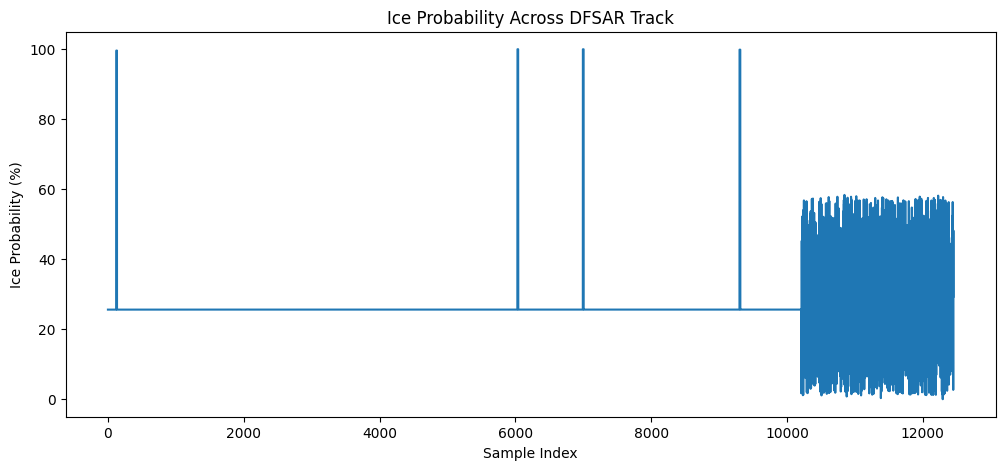

In [6]:
plt.figure(figsize=(12,5))

plt.plot(
    df["Ice_Probability"]
)

plt.title("Ice Probability Across DFSAR Track")
plt.xlabel("Sample Index")
plt.ylabel("Ice Probability (%)")

plt.show()

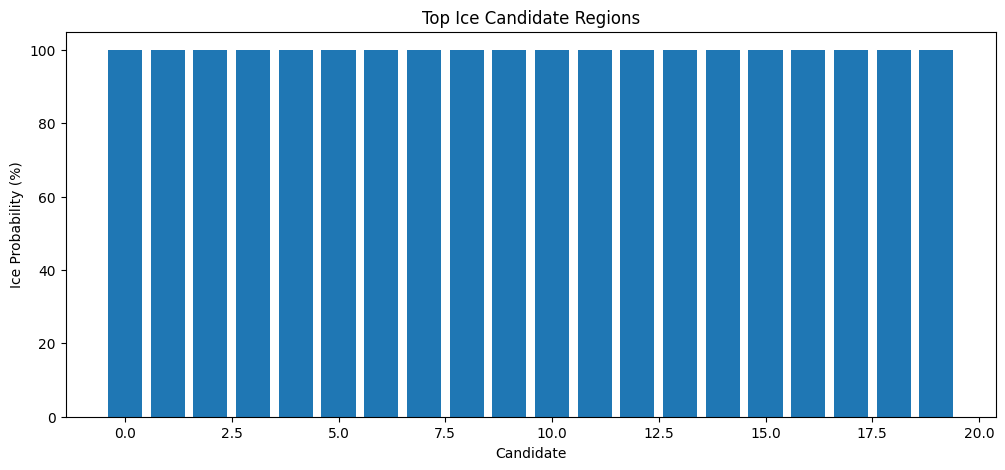

In [7]:
plt.figure(figsize=(12,5))

plt.bar(
    range(len(top_ice)),
    top_ice["Ice_Probability"]
)

plt.title("Top Ice Candidate Regions")
plt.xlabel("Candidate")
plt.ylabel("Ice Probability (%)")

plt.show()

In [8]:
top_ice.to_csv(
    "top_ice_candidates.csv",
    index=False
)

print("Top Ice Candidates Saved")

Top Ice Candidates Saved
